# Checking cell embeddings from adapted scConcept - Version 2, for model corpus40M-model30M

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import h5py
import scanpy as sc
import anndata as ad
import re
import json
from tqdm import tqdm

# Add the project root to sys.path so that 'src' can be imported
project_root = Path.cwd().parents[2]
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils.constants import get_full_path

## Helpers

In [2]:
# ---- USER SETTINGS ----

# Sampling
N_PER_SLIDE = 5000 
RANDOM_SEED = 0
rng = np.random.default_rng(RANDOM_SEED)

# Embedding choice: v2 provides only "cls_emb" (scConcept v0.2.x has no mean_emb).
# In v2 the cls embedding is 512-dim and L2-normalized.
EMB_KEY = "cls_emb"

# Optional: to use a global cap on total cells
MAX_TOTAL_CELLS = None       # e.g. 200_000 or None

In [3]:
# --- Extra metadata loaders for additional UMAP coloring ---

EMPTY_INT64 = np.array([], dtype=np.int64)


def xenium_cell_id_to_int_vec(cell_id_strs: np.ndarray) -> np.ndarray:
    """
    Vectorized Xenium cell_id string -> int64 conversion.
    """
    s = np.asarray(cell_id_strs, dtype="S16").reshape(-1)
    b = s.view(np.uint8).reshape(len(s), -1)[:, :8]
    vals = b.astype(np.int64) - ord("a")
    weights = (16 ** np.arange(7, -1, -1)).astype(np.int64)
    return (vals * weights).sum(axis=1) + 1



def _extract_cell_id_int_from_obs(obs: pd.DataFrame) -> np.ndarray:
    """
    Recover cell_id_int from an original per-slide AnnData .obs.
    Priority:
    1) obs['cell_id_int']
    2) obs['cell_id'] converted from Xenium string IDs
    """
    if "cell_id_int" in obs.columns:
        return obs["cell_id_int"].to_numpy(dtype=np.int64, copy=False)
    elif "cell_id" in obs.columns:
        return xenium_cell_id_to_int_vec(obs["cell_id"].astype(str).to_numpy())
    else:
        raise ValueError("No cell_id_int or cell_id column found in obs; cannot extract integer cell IDs.")



def _load_npz_dict(npz_obj, key: str) -> dict[str, np.ndarray]:
    """
    Load one dict[str, np.ndarray] saved inside cell_ids_sets.npz.
    """
    if key not in npz_obj.files:
        return {}

    obj = npz_obj[key]
    try:
        d = obj.item()   # expected for np.savez_compressed(dict_obj)
    except Exception:
        d = dict(obj)

    return {str(k): np.asarray(v, dtype=np.int64) for k, v in d.items()}



def load_train_test_maps(cell_ids_sets_path: str | Path) -> tuple[dict[str, np.ndarray], dict[str, np.ndarray]]:
    """
    Returns:
      train_only_by_slide: slide_id -> exclusive train cell IDs
      test_like_by_slide : slide_id -> exclusive (valid U test) cell IDs

    Note:
      valid is merged into test on purpose.
      Cells absent from these exclusive arrays will remain unlabeled (NA).
    """
    cell_ids_sets_path = Path(cell_ids_sets_path)
    npz = np.load(cell_ids_sets_path, allow_pickle=True)

    train_only_by_slide = _load_npz_dict(npz, "train_only_by_slide")
    valid_only_by_slide = _load_npz_dict(npz, "valid_only_by_slide")
    test_only_by_slide  = _load_npz_dict(npz, "test_only_by_slide")

    all_slide_ids = (
        set(train_only_by_slide)
        | set(valid_only_by_slide)
        | set(test_only_by_slide)
    )

    test_like_by_slide = {
        sid: np.union1d(
            valid_only_by_slide.get(sid, EMPTY_INT64),
            test_only_by_slide.get(sid, EMPTY_INT64),
        )
        for sid in all_slide_ids
    }

    return train_only_by_slide, test_like_by_slide



def load_slide_gene_counts(adatas_dir: str | Path, slide_ids: list[str]) -> dict[str, int]:
    """
    Load slide_id -> number of genes from the original per-slide AnnData files.

    Memory-safe:
      - opens each .h5ad in backed mode
      - reads only n_vars (equivalent to adata.var.shape[0])
      - closes the file immediately
    """
    adatas_dir = Path(adatas_dir)
    if not adatas_dir.exists():
        raise FileNotFoundError(f"adatas_dir not found: {adatas_dir}")

    h5ad_paths = list(adatas_dir.rglob("*.h5ad"))
    if len(h5ad_paths) == 0:
        raise FileNotFoundError(f"No .h5ad files found under {adatas_dir}")

    h5ad_by_slide = {}
    for p in h5ad_paths:
        if p.stem in h5ad_by_slide:
            raise ValueError(
                f"Multiple .h5ad files found for slide_id '{p.stem}': "
                f"{h5ad_by_slide[p.stem]} and {p}"
            )
        h5ad_by_slide[p.stem] = p

    gene_count_by_slide = {}
    missing = []
    for slide_id in map(str, slide_ids):
        h5ad_path = h5ad_by_slide.get(slide_id)
        if h5ad_path is None:
            missing.append(slide_id)
            continue

        slide_adata = ad.read_h5ad(h5ad_path, backed="r")
        try:
            gene_count_by_slide[slide_id] = int(slide_adata.n_vars)
        finally:
            if getattr(slide_adata, "file", None) is not None:
                slide_adata.file.close()

    if missing:
        raise FileNotFoundError(
            "Missing .h5ad file(s) for slide_id(s): "
            + ", ".join(sorted(missing))
            + f" under {adatas_dir}"
        )

    return gene_count_by_slide



def load_slide_total_rna_counts(adatas_dir: str | Path, slide_ids: list[str]) -> pd.Series:
    """
    Load per-cell total RNA counts from the original per-slide AnnData files.

    Returns:
        pandas Series: Indexed by MultiIndex (slide_id, cell_id_int), with float64 values equal to total RNA counts per cell.

    - If obs['total_counts'] already exists in the original per-slide AnnData, it is reused directly.
    - Otherwise, totals are computed as adata.X.sum(axis=1).
    """
    adatas_dir = Path(adatas_dir)
    if not adatas_dir.exists():
        raise FileNotFoundError(f"adatas_dir not found: {adatas_dir}")

    h5ad_paths = list(adatas_dir.rglob("*.h5ad"))
    if len(h5ad_paths) == 0:
        raise FileNotFoundError(f"No .h5ad files found under {adatas_dir}")

    h5ad_by_slide = {}
    for p in h5ad_paths:
        if p.stem in h5ad_by_slide:
            raise ValueError(
                f"Multiple .h5ad files found for slide_id '{p.stem}': "
                f"{h5ad_by_slide[p.stem]} and {p}"
            )
        h5ad_by_slide[p.stem] = p

    total_counts_parts = []
    missing = []
    for slide_id in map(str, slide_ids):
        h5ad_path = h5ad_by_slide.get(slide_id)
        if h5ad_path is None:
            missing.append(slide_id)
            continue

        slide_adata = ad.read_h5ad(h5ad_path, backed="r")
        try:
            cell_id_int = _extract_cell_id_int_from_obs(slide_adata.obs)

            if "total_counts" in slide_adata.obs.columns:
                total_counts = slide_adata.obs["total_counts"].to_numpy(dtype=np.float64, copy=False)
            else:
                total_counts = np.asarray(slide_adata.X.sum(axis=1)).reshape(-1).astype(np.float64, copy=False)

            idx = pd.MultiIndex.from_arrays(
                [np.repeat(slide_id, len(cell_id_int)), cell_id_int],
                names=["slide_id", "cell_id_int"],
            )
            s = pd.Series(total_counts, index=idx, name="total_rna_counts")
            if not s.index.is_unique:
                raise ValueError(f"Duplicate (slide_id, cell_id_int) keys found in {h5ad_path}")

            total_counts_parts.append(s)
        finally:
            if getattr(slide_adata, "file", None) is not None:
                slide_adata.file.close()

    if missing:
        raise FileNotFoundError(
            "Missing .h5ad file(s) for slide_id(s): "
            + ", ".join(sorted(missing))
            + f" under {adatas_dir}"
        )

    return pd.concat(total_counts_parts)



def annotate_obs_with_extra_metadata(
    adata: ad.AnnData,
    cell_ids_sets_path: str | Path | None = None,
    adatas_dir: str | Path | None = None,
):
    """
    Adds to adata.obs:
      - dataset_split : categorical {"train", "test"} with NA for unlabeled cells
      - total_rna_counts : numeric total RNA counts per cell from original per-slide adata
      - gene_count : numeric number of genes in the original per-slide adata.var
    """
    if "slide_id" not in adata.obs.columns:
        print("No slide_id column found in obs; skipping extra metadata annotations.")
        return

    # ---- dataset_split (train vs test, with valid merged into test)
    if cell_ids_sets_path is not None:
        if "cell_id_int" not in adata.obs.columns:
            print("No cell_id_int column found in obs; skipping dataset_split annotation.")
        else:
            try:
                train_only_by_slide, test_like_by_slide = load_train_test_maps(cell_ids_sets_path)

                split = pd.Series(pd.NA, index=adata.obs.index, dtype="object")

                for sid, idx in adata.obs.groupby("slide_id", observed=True).groups.items():
                    sid = str(sid)
                    cell_ids = adata.obs.loc[idx, "cell_id_int"].to_numpy(dtype=np.int64, copy=False)

                    is_train = np.isin(cell_ids, train_only_by_slide.get(sid, EMPTY_INT64))
                    is_test  = np.isin(cell_ids, test_like_by_slide.get(sid, EMPTY_INT64))

                    labels = np.full(cell_ids.shape[0], pd.NA, dtype=object)
                    labels[is_train] = "train"
                    labels[~is_train & is_test] = "test"
                    split.loc[idx] = labels

                adata.obs["dataset_split"] = pd.Categorical(split, categories=["train", "test"])

                n_missing = adata.obs["dataset_split"].isna().sum()
                if n_missing > 0:
                    print(
                        f"Warning: {n_missing} cells have no exclusive split label "
                        f"(likely absent from cell_ids_sets.npz to avoid patch overlap across sets)."
                    )
            except Exception as e:
                print(f"Could not load/annotate dataset_split from {cell_ids_sets_path}: {e}")

    # ---- total_rna_counts from original per-slide adata.obs / adata.X
    if adatas_dir is not None:
        if "cell_id_int" not in adata.obs.columns:
            print("No cell_id_int column found in obs: skipping total_rna_counts annotation.")
        else:
            try:
                slide_ids = adata.obs["slide_id"].astype(str).unique().tolist()
                total_counts_map = load_slide_total_rna_counts(adatas_dir, slide_ids=slide_ids)

                lookup_index = pd.MultiIndex.from_arrays(
                    [
                        adata.obs["slide_id"].astype(str).to_numpy(),
                        adata.obs["cell_id_int"].to_numpy(dtype=np.int64, copy=False),
                    ],
                    names=["slide_id", "cell_id_int"],
                )

                adata.obs["total_rna_counts"] = total_counts_map.reindex(lookup_index).to_numpy()

                n_missing = adata.obs["total_rna_counts"].isna().sum()
                if n_missing > 0:
                    print(f"Warning: {n_missing} cells have no total_rna_counts mapping.")
            except Exception as e:
                print(f"Could not load/annotate total_rna_counts from {adatas_dir}: {e}")

    # ---- gene_count from original per-slide adata.var
    if adatas_dir is not None:
        try:
            slide_ids = adata.obs["slide_id"].astype(str).unique().tolist()
            gene_count_map = load_slide_gene_counts(adatas_dir, slide_ids=slide_ids)
            adata.obs["gene_count"] = (
                adata.obs["slide_id"]
                .astype(str)
                .map(gene_count_map)
                .astype(float)
            )

            n_missing = adata.obs["gene_count"].isna().sum()
            if n_missing > 0:
                print(f"Warning: {n_missing} cells have no gene_count mapping.")
        except Exception as e:
            print(f"Could not load/annotate gene_count from {adatas_dir}: {e}")

In [4]:
# --- 1) Discover slides + sanity checks ---

def discover_slides(emb_dir: Path, ct_dir: Path, slide_ids=None):
    
    assert emb_dir.exists(), f"emb_dir not found: {emb_dir}"
    assert ct_dir.exists(), f"ct_dir not found: {ct_dir}"

    h5_files = sorted(emb_dir.glob("*.h5"))
    assert len(h5_files) > 0, f"No .h5 files found in {emb_dir}"

    if slide_ids is None:
        slide_ids = [p.stem for p in h5_files]  # <slide_id>.h5 -> slide_id

    # Keep only those that exist as H5
    available = {p.stem for p in h5_files}
    slide_ids = [sid for sid in slide_ids if sid in available]
    assert len(slide_ids) > 0, "No slide IDs found after filtering to existing .h5 files"

    print(f"Found {len(slide_ids)} slides for embedding loading.")
    print("Slides:", slide_ids)

    return slide_ids

In [5]:
# --- 2) Load sampled data across slides ---

def load_sample_one_slide(
    slide_id: str,
    emb_path: Path,
    ct_path: Path,
    n_per_slide: int,
    emb_key: str = "cls_emb",
    rng: np.random.Generator | None = None,
):
    """
    Returns:
      X: (n, d) float32
      obs_df: pandas DataFrame with columns [slide_id, cell_id_int, cell_id, cell_type]
    """
    if rng is None:
        rng = np.random.default_rng(0)

    # ---- read embeddings from H5
    with h5py.File(emb_path, "r") as f:
        if "cell_id_int" not in f:
            raise KeyError(f"{emb_path} missing dataset 'cell_id_int'")
        if emb_key not in f:
            raise KeyError(f"{emb_path} missing dataset '{emb_key}' (available: {list(f.keys())})")

        cell_id_int = f["cell_id_int"][:]  # int64, shape (n_cells,)
        X_all = f[emb_key]                 # H5 dataset: (n_cells, d) float16/float32

        n_cells = cell_id_int.shape[0]
        if n_cells == 0:
            return None, None

        n_take = min(n_per_slide, n_cells)
        idx = rng.choice(n_cells, size=n_take, replace=False)
        idx.sort()  # improves HDF5 read efficiency

        X = X_all[idx].astype(np.float32, copy=False)
        cell_id_int_s = cell_id_int[idx].astype(np.int64, copy=False)

        # if stored, cell_id string can be useful for debugging
        if "cell_id" in f:
            # stored as fixed-width bytes; decode to str
            cell_id_s = f["cell_id"][idx].astype("S").astype(str)
        else:
            cell_id_s = None

    # ---- read cell type mapping (Parquet)
    # parquet schema: columns ["cell_id", "cell_type"]
    # cell_id is Xenium string, convert parquet cell_id strings -> int, then join on int.
    ct = None
    if ct_path.exists():
        ct = pd.read_parquet(ct_path, columns=["cell_id", "cell_type"])
    else:
        # no annotations for this slide
        ct = pd.DataFrame({"cell_id": [], "cell_type": []})

    if len(ct) > 0:
        ct_int = xenium_cell_id_to_int_vec(ct["cell_id"].astype(str).to_numpy())
        ct = ct.assign(cell_id_int=ct_int)
        # reduce to mapping for faster join
        ct = ct[["cell_id_int", "cell_type"]]
        # if duplicates exist, raise an error
        if ct["cell_id_int"].duplicated().any():
            raise ValueError(f"Duplicate cell_id_int in cell type mapping for slide {slide_id}")
    else:
        ct = pd.DataFrame({"cell_id_int": np.array([], dtype=np.int64), "cell_type": pd.Categorical([])})

    # ---- build obs df for sampled cells
    obs_df = pd.DataFrame({
        "slide_id": slide_id,
        "cell_id_int": cell_id_int_s,
    })
    if cell_id_s is not None:
        obs_df["cell_id"] = cell_id_s

    # join cell_type on int id
    obs_df = obs_df.merge(ct, on="cell_id_int", how="left")
    # keep categorical (nice for plotting legend order)
    if "cell_type" in obs_df.columns:
        obs_df["cell_type"] = obs_df["cell_type"].astype("category")

    return X, obs_df


def load_sample_all_slides(emb_dir: Path, ct_dir: Path, slide_ids=None):
    
    Xs = []
    obs_list = []
    total = 0

    for sid in tqdm(slide_ids):
        emb_path = emb_dir / f"{sid}.h5"
        ct_path  = ct_dir  / f"cID2cT_{sid}.parquet"

        X, obs_df = load_sample_one_slide(
            slide_id=sid,
            emb_path=emb_path,
            ct_path=ct_path,
            n_per_slide=N_PER_SLIDE,
            emb_key=EMB_KEY,
            rng=rng,
        )
        if X is None:
            continue

        Xs.append(X)
        obs_list.append(obs_df)
        total += X.shape[0]

        if MAX_TOTAL_CELLS is not None and total >= MAX_TOTAL_CELLS:
            break

    X = np.vstack(Xs)
    obs = pd.concat(obs_list, ignore_index=True)

    print("Total sampled cells:", X.shape[0])
    print("Embedding dim:", X.shape[1])
    print(obs.head())

    return X, obs

In [6]:
# --- 3) Build AnnData + compute UMAP ---

def build_adata_umap(X: np.ndarray, obs: pd.DataFrame, n_pcs: int, n_neighbors: int) -> ad.AnnData:

    adata = ad.AnnData(X=X, obs=obs)

    # Ensure categories for clean plotting
    adata.obs["slide_id"] = adata.obs["slide_id"].astype("category")
    if "cell_type" in adata.obs.columns:
        adata.obs["cell_type"] = adata.obs["cell_type"].astype("category")

    # PCA
    sc.pp.pca(adata, n_comps=min(n_pcs, adata.n_vars), svd_solver="randomized")
    sc.pl.pca_variance_ratio(adata, n_pcs=min(n_pcs, adata.n_vars), log=True, show=True)
    
    # Neighbors + UMAP
    print("Computing neighbors using n_pcs =", min(n_pcs, adata.obsm["X_pca"].shape[1]), " and n_neighbors =", n_neighbors)
    sc.pp.neighbors(adata, n_neighbors=n_neighbors, n_pcs=min(n_pcs, adata.obsm["X_pca"].shape[1]))
    sc.tl.umap(adata)

    return adata

In [7]:
# --- 4) Plots ---

def plot_umap(
    adata: ad.AnnData,
    slide_status_path: str,
    cell_ids_sets_path: str | Path | None = None,
    adatas_dir: str | Path | None = None,
):

    # Load slide_status mapping
    try:
        with open(slide_status_path, "r") as f:
            slide_status_map = json.load(f)
    except Exception as e:
        print(f"Could not load slide_status.json: {e}")
        slide_status_map = {}

    # Create tissue_type
    if "slide_id" in adata.obs.columns:
        adata.obs["tissue_type"] = (
            adata.obs["slide_id"]
            .astype(str)
            .str.replace(r"_s\d+$", "", regex=True)
            .astype("category")
        )

        # Create slide_status
        adata.obs["slide_status"] = (
            adata.obs["slide_id"]
            .map(slide_status_map)
            .astype("category")
        )
    else:
        print("No slide_id column found in obs; skipping derived annotations.")

    # Additional metadata used only for coloring (does not affect UMAP geometry)
    annotate_obs_with_extra_metadata(
        adata,
        cell_ids_sets_path=cell_ids_sets_path,
        adatas_dir=adatas_dir,
    )

    # UMAP: slide_id ---
    if "slide_id" in adata.obs.columns:
        sc.pl.umap(
            adata,
            color="slide_id",
            title=f"scConcept ({EMB_KEY}) UMAP — slide_id (N={adata.n_obs})",
            wspace=0.3,
        )

    # UMAP: tissue_type ---
    if "tissue_type" in adata.obs.columns:
        sc.pl.umap(
            adata,
            color="tissue_type",
            title=f"scConcept ({EMB_KEY}) UMAP — tissue_type (N={adata.n_obs})",
            wspace=0.3,
            na_color="lightgray",
        )

    # UMAP: slide_status ---
    if "slide_status" in adata.obs.columns:
        sc.pl.umap(
            adata,
            color="slide_status",
            palette={"healthy": "green", "cancerous": "red"},
            title=f"scConcept ({EMB_KEY}) UMAP — SLIDE_status (NOT cell status) (N={adata.n_obs})",
            wspace=0.3,
            na_color="lightgray",
        )

        # Warn if missing mappings
        n_missing = adata.obs["slide_status"].isna().sum()
        if n_missing > 0:
            print(f"Warning: {n_missing} cells have no slide_status mapping.")

    # UMAP: dataset_split (train vs test, with valid merged into test) ---
    if "dataset_split" in adata.obs.columns:
        sc.pl.umap(
            adata,
            color="dataset_split",
            palette={"train": "steelblue", "test": "darkorange"},
            title=f"scConcept ({EMB_KEY}) UMAP — dataset_split (N={adata.n_obs})",
            wspace=0.3,
            na_color="lightgray",
        )

    # UMAP: total_rna_counts ---
    if "total_rna_counts" in adata.obs.columns:
        adata.obs["log1p_total_rna_counts"] = np.log1p(adata.obs["total_rna_counts"].astype(float))
        sc.pl.umap(
            adata,
            color="log1p_total_rna_counts",
            vmax="p99",
            title=f"scConcept ({EMB_KEY}) UMAP — log1p(total RNA counts per cell), clipped at p99 (N={adata.n_obs})",
            wspace=0.3,
            na_color="lightgray",
        )

    # UMAP: gene_count ---
    if "gene_count" in adata.obs.columns:
        sc.pl.umap(
            adata,
            color="gene_count",
            title=f"scConcept ({EMB_KEY}) UMAP — gene_count from original adata.var (N={adata.n_obs})",
            wspace=0.3,
            na_color="lightgray",
        )

    # UMAP: cell_type ---
    if "cell_type" in adata.obs.columns:
        sc.pl.umap(
            adata,
            color="cell_type",
            title=f"scConcept ({EMB_KEY}) UMAP — cell_type (N={adata.n_obs})",
            wspace=0.3,
            na_color="lightgray",
        )
    else:
        print("No cell_type column found in obs; skipping cell_type UMAP.")

## scConcept training_7

In [8]:
training_id = "training_7"
ct_cat_id = "ct_1"
dataset_id = "ds_ct1_20x_224_o112"
training_dataset_id = "ds_ct1_20x_224_o112_1"

In [9]:
EMB_DIR = get_full_path('train', 'trainings', 'trainings_scConcept', training_id, 'embeddings')  # contains <slide_id>.h5 with scConcept cell embeddings
CT_DIR  = get_full_path('STHELAR_HistoST', 'cID2cT', ct_cat_id)  # contains cID2cT_<slide_id>.parquet with cell type mappings
TRAINING_DATASET_DIR = get_full_path('train', 'training_datasets', dataset_id, training_dataset_id)
CELL_IDS_SETS_PATH = TRAINING_DATASET_DIR / "cell_ids_sets.npz"
ADATAS_DIR = TRAINING_DATASET_DIR / "adatas"
SLIDE_IDS = None   # e.g. ["heart_s0","breast_s0",...] or None to auto-detect from *.h5

In [10]:
slide_ids = discover_slides(EMB_DIR, CT_DIR, slide_ids=SLIDE_IDS)

Found 28 slides for embedding loading.
Slides: ['breast_s0', 'breast_s1', 'breast_s3', 'breast_s6', 'cervix_s0', 'colon_s1', 'colon_s2', 'heart_s0', 'kidney_s0', 'kidney_s1', 'kidney_s2', 'liver_s0', 'liver_s1', 'lung_s1', 'lung_s3', 'lymph_node_s0', 'ovary_s0', 'ovary_s1', 'pancreatic_s0', 'pancreatic_s1', 'pancreatic_s2', 'prostate_s0', 'skin_s1', 'skin_s2', 'skin_s3', 'skin_s4', 'tonsil_s0', 'tonsil_s1']


In [11]:
X, obs = load_sample_all_slides(EMB_DIR, CT_DIR, slide_ids=slide_ids)

100%|██████████| 28/28 [01:52<00:00,  4.02s/it]

Total sampled cells: 140000
Embedding dim: 512
    slide_id  cell_id_int     cell_type
0  breast_s0          109  Blood_vessel
1  breast_s0          128   Specialized
2  breast_s0          173   Specialized
3  breast_s0          219    Epithelial
4  breast_s0          343    Epithelial


$HOME/miniforge3/envs/histost/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


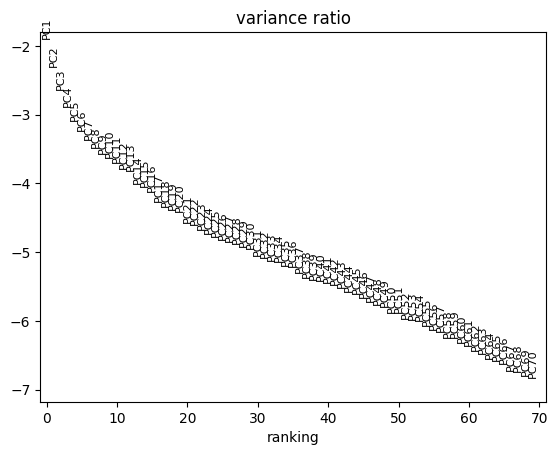

Computing neighbors using n_pcs = 70  and n_neighbors = 30


In [12]:
adata = build_adata_umap(X, obs, n_pcs=70, n_neighbors=30)

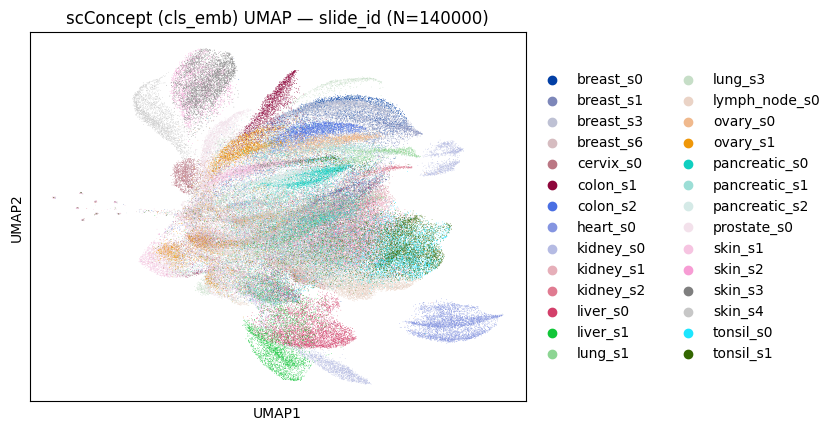

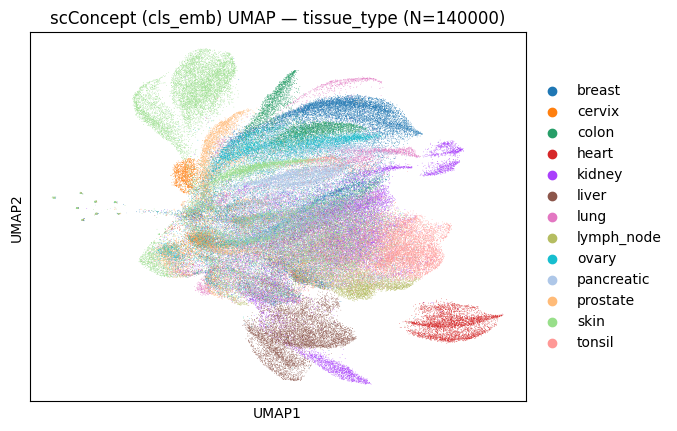

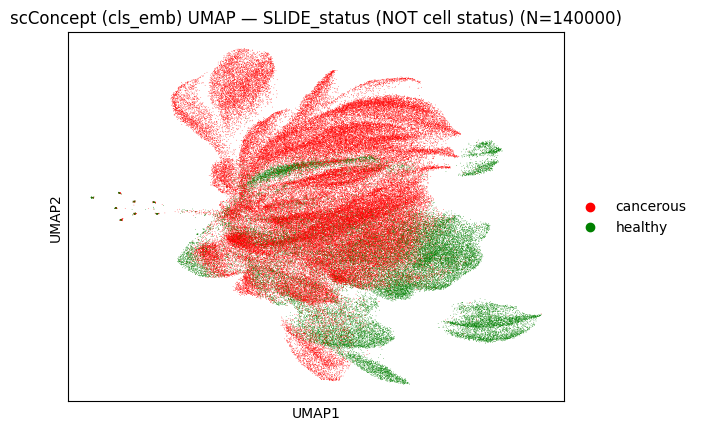

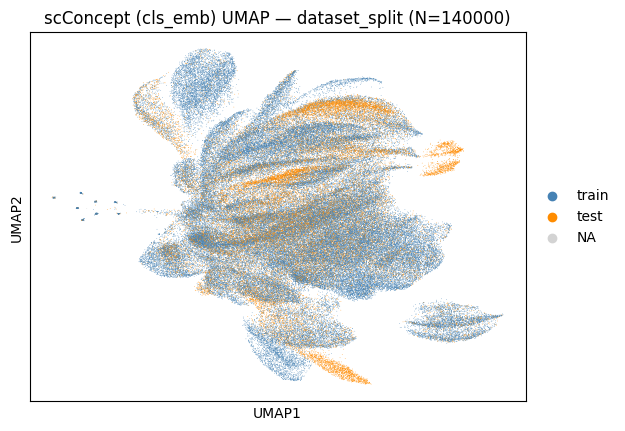

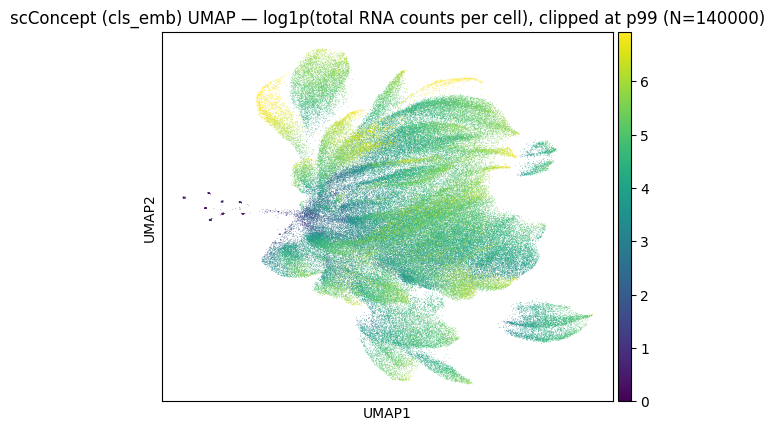

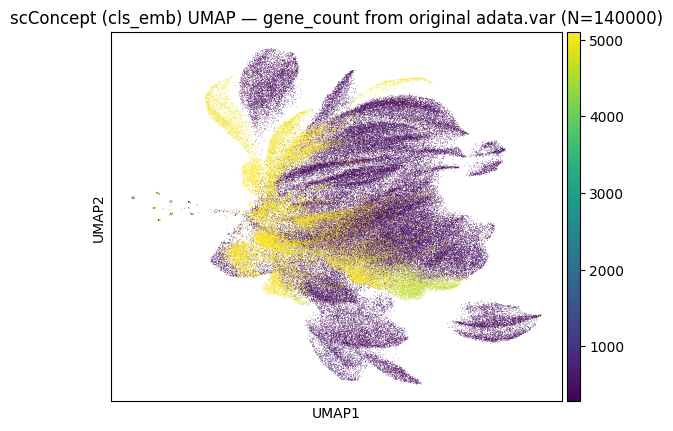

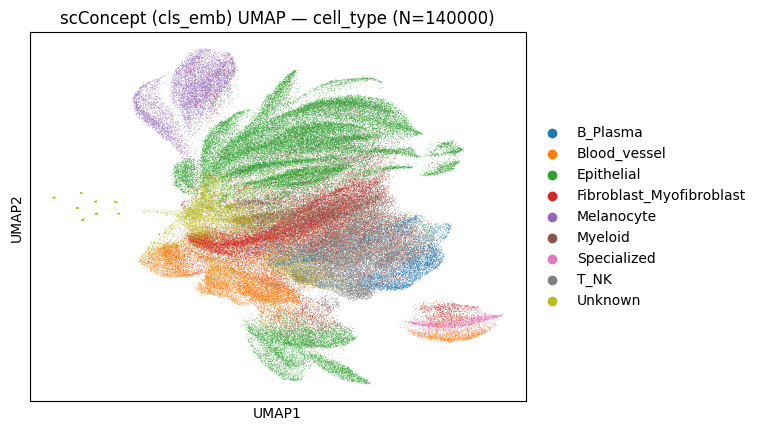

In [13]:
plot_umap(
    adata,
    slide_status_path="/path/to/ALHENA-paper/data/slide_status.json",
    cell_ids_sets_path=CELL_IDS_SETS_PATH,
    adatas_dir=ADATAS_DIR,
)